# BOGO promotions: Could smarter targeting beat the original campaign?

**Business-first causal inference | CausalForestDML vs the actual historical campaign and simple CRM rules**

**Goal:** Find customers likely to make **additional profitable purchases** because of BOGO, then compare estimated targeting profits with **what happened in the original campaign**.

**Roadmap:** 1. Business questions → 2. Data & methodology → 3. Experiments → 4. Business conclusion.

## 1. Business questions & the causality problem

Offering **Buy One Get One (BOGO)** can create new orders, but giving away products to customers who would have purchased anyway can reduce profit.

**What we want to know:**
1. Does CausalForestDML generate more profit than the original campaign's actual offer allocation?
2. Which customer characteristics are associated with higher **predicted uplift**?
3. How do profit-based targeting and the actual campaign compare with simple CRM rules based on past spending, BOGO usage, discount history, and recency?
4. Would the best targeting decision change if BOGO promotion costs increased?

**Why causal inference?** Customers who buy after receiving BOGO may have bought anyway. We estimate the *additional probability of purchasing because of BOGO*, not simply the probability of purchasing.

`Uplift = P(Buy with BOGO) − P(Buy without BOGO)`

For example, an individual uplift of **+0.05** means an estimated **5-percentage-point** increase in purchase probability. An average uplift of +0.05 suggests approximately **5 additional purchases per 100 customers**, on average—not guaranteed orders.

## 2. Methodology & dataset

**Source:** [Customer Retention dataset](https://www.kaggle.com/datasets/davinwijaya/customer-retention). We keep customers whose historical `offer` was **Buy One Get One** or **No Offer** and exclude the **Discount** group.

| Field | Business meaning |
|---|---|
| `history` | Customer's past spending |
| `recency` | Time since the last purchase; higher means longer ago |
| `used_bogo`, `used_discount` | Whether a customer previously used these promotions |
| `zip_code` | Area category recorded in the dataset |
| `channel` | Customer's recorded marketing channel |
| `is_referral` | Whether the customer was referred |
| `offer` | Promotion **actually assigned in the historical campaign** |
| `conversion` | Whether the customer actually purchased (1 = yes, 0 = no) |

**Approach:** Train CausalForestDML on **80% of customers**. Use the remaining **20% as a held-out test set** to compare strategies for the **same set of customers**. There is no separate validation split.

**Two different kinds of numbers:**
- **Original campaign (observed):** Calculate contribution profit from offers **actually sent** and purchases **actually made** in the historical test data, under our assumed product and messaging costs.
- **Alternative strategies (estimated):** Estimate what customers *would* have purchased if offers were assigned by CausalForestDML or another CRM rule. We combine purchase predictions with historical outcomes to adjust the estimates (AIPW).

We compare both with **No Offer**, which is an **estimated counterfactual baseline**, not an observed no-promotion campaign for everyone.

**Key limitation:** The data does not confirm whether the original offers were assigned randomly. The causal comparison relies on randomized assignment **or suitable no-unmeasured-confounding assumptions**. The USD 25 price, USD 5 item cost, USD 0.20 sending cost, and 100% BOGO redemption are **illustrative assumptions**, not fields in the dataset.

### Setup: packages and editable business assumptions

The example assumes a **USD 25 sale**, a **USD 5 cost per item**, and **USD 0.20 per offer sent**. The free item is the **same product** as the paid item, so both have the same unit cost.

In [11]:
# Run once in Colab / Jupyter. Avoid sklift.viz (incompatible with some scikit-learn versions).
%pip -q install "econml>=0.17,<0.18"

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from econml.dml import CausalForestDML

SEED = 24

# Editable unit economics: buying one item gives one identical free item.
REVENUE_PER_ORDER = 25.00        # Sales revenue for one paid item
ITEM_COST = 5.00                # Unit cost of BOTH the paid and the free item
SEND_COST_PER_OFFER = 0.20      # Paid for every BOGO offer sent
BOGO_REDEMPTION_PER_CONVERSION = 1.00  # Assume every BOGO purchase redeems the free item
COST_RATES = [0.10, 0.20, 0.30, 0.40, 0.50]

MARGIN_PER_CONVERSION = REVENUE_PER_ORDER - ITEM_COST
FREE_ITEM_COST = ITEM_COST
FOREST_LABEL = 'CausalForestDML (profit targeted)'

assert REVENUE_PER_ORDER > ITEM_COST >= 0
assert SEND_COST_PER_OFFER >= 0
assert 0 <= BOGO_REDEMPTION_PER_CONVERSION <= 1
assert all(rate * REVENUE_PER_ORDER >= SEND_COST_PER_OFFER for rate in COST_RATES)

print(f'Normal sale contribution: USD {REVENUE_PER_ORDER:.2f} revenue - '
      f'USD {ITEM_COST:.2f} paid-item cost = USD {MARGIN_PER_CONVERSION:.2f}.')
print(f'Redeemed BOGO contribution: USD {REVENUE_PER_ORDER - 2*ITEM_COST:.2f} '
      f'per purchase before sending costs (plus USD {SEND_COST_PER_OFFER:.2f} per offer sent).')

Normal sale contribution: USD25.00 revenue - USD5.00 paid-item cost = USD20.00.
Redeemed BOGO contribution: USD15.00 per purchase before sending costs (plus USD0.20 per offer sent).


### Load historical campaign data

In [13]:
# Replace with the CSV file path if the public link is unavailable.
DATA_URL = 'https://drive.google.com/uc?export=download&id=1vjqiiAWpBv6IO0Fd-Rz8BTgXrIZy1Q2w'
try:
    raw = pd.read_csv(DATA_URL)
except Exception as exc:
    raise RuntimeError('Could not load the campaign CSV. Update DATA_URL to a working URL or local path.') from exc

features = ['recency', 'history', 'used_discount', 'used_bogo',
            'zip_code', 'is_referral', 'channel']
required = features + ['offer', 'conversion']
missing = sorted(set(required) - set(raw.columns))
if missing:
    raise ValueError(f'Missing required dataset columns: {missing}')

raw = (raw.loc[raw['offer'].isin(['No Offer', 'Buy One Get One']), required]
       .dropna().reset_index(drop=True).copy())
raw['treatment'] = raw['offer'].map({'No Offer': 0, 'Buy One Get One': 1}).astype(int)
raw['conversion'] = raw['conversion'].astype(int)
assert raw['conversion'].isin([0, 1]).all()
assert raw['used_bogo'].isin([0, 1]).all()
assert raw['treatment'].nunique() == 2, 'Both treatment groups are required.'

print(f'Campaign customers after excluding Discount: {len(raw):,}')
display(raw.head())
display(raw.groupby('offer').agg(
    customers=('conversion', 'size'),
    observed_conversion_rate=('conversion', 'mean')))

Campaign customers after excluding Discount: 42,693


,recency,history,used_discount,used_bogo,zip_code,is_referral,channel,offer,conversion,treatment
0,10,142.44,1,0,Surburban,0,Phone,Buy One Get One,0,1
1,6,329.08,1,1,Rural,1,Web,No Offer,0,0
2,7,180.65,0,1,Surburban,1,Web,Buy One Get One,0,1
3,2,45.34,1,0,Urban,0,Web,Buy One Get One,0,1
4,6,134.83,0,1,Surburban,0,Phone,Buy One Get One,1,1


,customers,observed_conversion_rate
offer,,
Buy One Get One,21387,0.151400
No Offer,21306,0.106167


**Observed campaign result:** Customers who received BOGO converted at **15.14%**, versus **10.62%** for customers who received No Offer—a difference of **4.52 percentage points**.

But **did the actual historical campaign make the most profit after costs?** We will compare its observed test-set contribution with estimates for smarter alternative targeting strategies. The historical assignment itself is **not proven to be random**.

### Split the data: 80% train, 20% test

In [14]:
# One-hot encoding explicitly includes ZIP/area and CHANNEL in the causal forest.
X_all = pd.get_dummies(raw[features], columns=['zip_code', 'channel'],
                       drop_first=True, dtype=int)
all_idx = np.arange(len(raw))
train_idx, test_idx = train_test_split(
    all_idx, test_size=0.2, random_state=SEED, stratify=raw['treatment'])

def split(indices):
    return (X_all.iloc[indices].reset_index(drop=True),
            raw['treatment'].iloc[indices].to_numpy(dtype=int),
            raw['conversion'].iloc[indices].to_numpy(dtype=int))

X_train, t_train, y_train = split(train_idx)
X_test, t_test, y_test = split(test_idx)

AVG_SPENDING = float(raw.iloc[train_idx]['history'].mean())
AVG_RECENCY = float(raw.iloc[train_idx]['recency'].mean())
P_BOGO = float(t_train.mean())
assert 0.05 < P_BOGO < 0.95, 'Too few customers in one historical treatment arm.'

print(f'Train: {len(y_train):,} customers | Test: {len(y_test):,} customers')
#print(f'Historical BOGO assignment rate in train: {P_BOGO:.1%}')
#print(f'Average previous spending: USD {AVG_SPENDING:,.2f}')
#print(f'Average recency: {AVG_RECENCY:,.2f}')
#print('ZIP/area and channel feature columns:',
#      [c for c in X_train if c.startswith(('zip_code_', 'channel_'))])

Train: 34,154 customers | Test: 8,539 customers


## 3. Experiments

### 3.1 Learn individual BOGO uplift with CausalForestDML

**CausalForestDML** looks for customers whose chance of purchasing is expected to **increase because of BOGO**, based on pre-campaign information. A positive uplift does not automatically imply the offer is profitable.

Average predicted BOGO uplift in training: +4.68% (percentage-point difference)
Share of training customers with positive predicted uplift: 87.8%


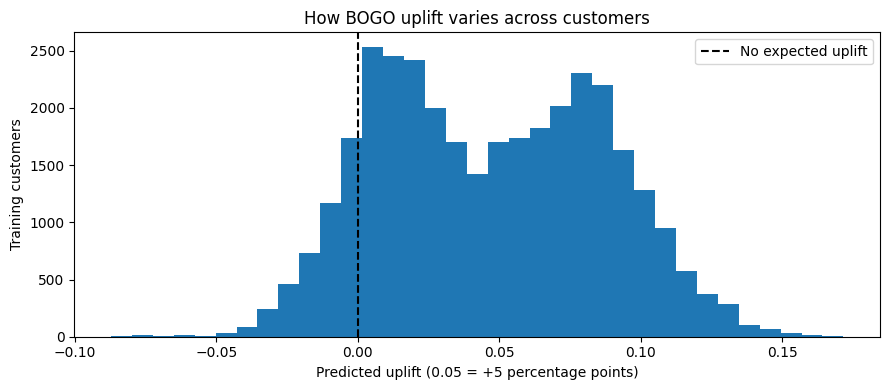

In [15]:
def conversion_model():
    return RandomForestClassifier(
        n_estimators=120, max_depth=10, min_samples_leaf=30,
        n_jobs=-1, random_state=SEED)

# Cross-fitting happens within TRAIN; no additional validation data is created.
# Historical treatment assignment is assumed randomized and must be verified.
forest = CausalForestDML(
    model_y=conversion_model(),
    model_t=DummyClassifier(strategy='prior'),
    discrete_outcome=True, discrete_treatment=True,
    n_estimators=200, min_samples_leaf=25, cv=3,
    random_state=SEED, n_jobs=-1)
forest.fit(y_train, t_train, X=X_train)

uplift_train = np.asarray(forest.effect(X_train)).reshape(-1)
uplift_test = np.asarray(forest.effect(X_test)).reshape(-1)

print(f'Average predicted BOGO uplift in training: {uplift_train.mean():+.2%} '
      '(percentage-point difference)')
print(f'Share of training customers with positive predicted uplift: '
      f'{(uplift_train > 0).mean():.1%}')
plt.figure(figsize=(9, 4))
plt.hist(uplift_train, bins=35)
plt.axvline(0, color='black', linestyle='--', label='No expected uplift')
plt.xlabel('Predicted uplift (0.05 = +5 percentage points)')
plt.ylabel('Training customers')
plt.title('How BOGO uplift varies across customers')
plt.legend()
plt.tight_layout()
plt.show()


**Average uplift:** Average uplift is **+4.68 percentage points**, meaning BOGO is predicted to generate approximately **5 additional purchases per 100 customers**.The following sections check whether those extra purchases cover the promotion costs.

**Positive predicted uplift**: Although **87.8%** of training customers are predicted to have positive uplift, the remaining **12.2%** may be less responsive to the BOGO offer. This could reflect a lack of interest, offer fatigue, annoyance from receiving promotional emails, or other individual preferences. Therefore, sending BOGO offers to everyone may not be the most effective strategy.

**Individual uplift:** If a customer's chance of buying would be **10% without BOGO** and **18% with BOGO**, their uplift is **+8 percentage points**. That is an estimated increase in purchase probability, not a promise that this customer will buy.

### 3.2 Who are the high-uplift customers? (feature charts)

This section profiles **which customer groups the model expects to benefit more from BOGO**.

For simple business reporting, **high uplift = the top 20% of training customers by predicted uplift**. The charts below use **training customers** and summarize the model's predictions across key features:
- **History spending**
- **Recency**
- **Used BOGO before**
- **ZIP code**
- **Channel**
- **Used discount before**
- **Referred**

These charts are **descriptive, not causal proof**. They help explain where the model sees stronger BOGO response, but they do not prove that a single feature causes the uplift.

High-uplift threshold (top ~20% of training customers): +8.52%


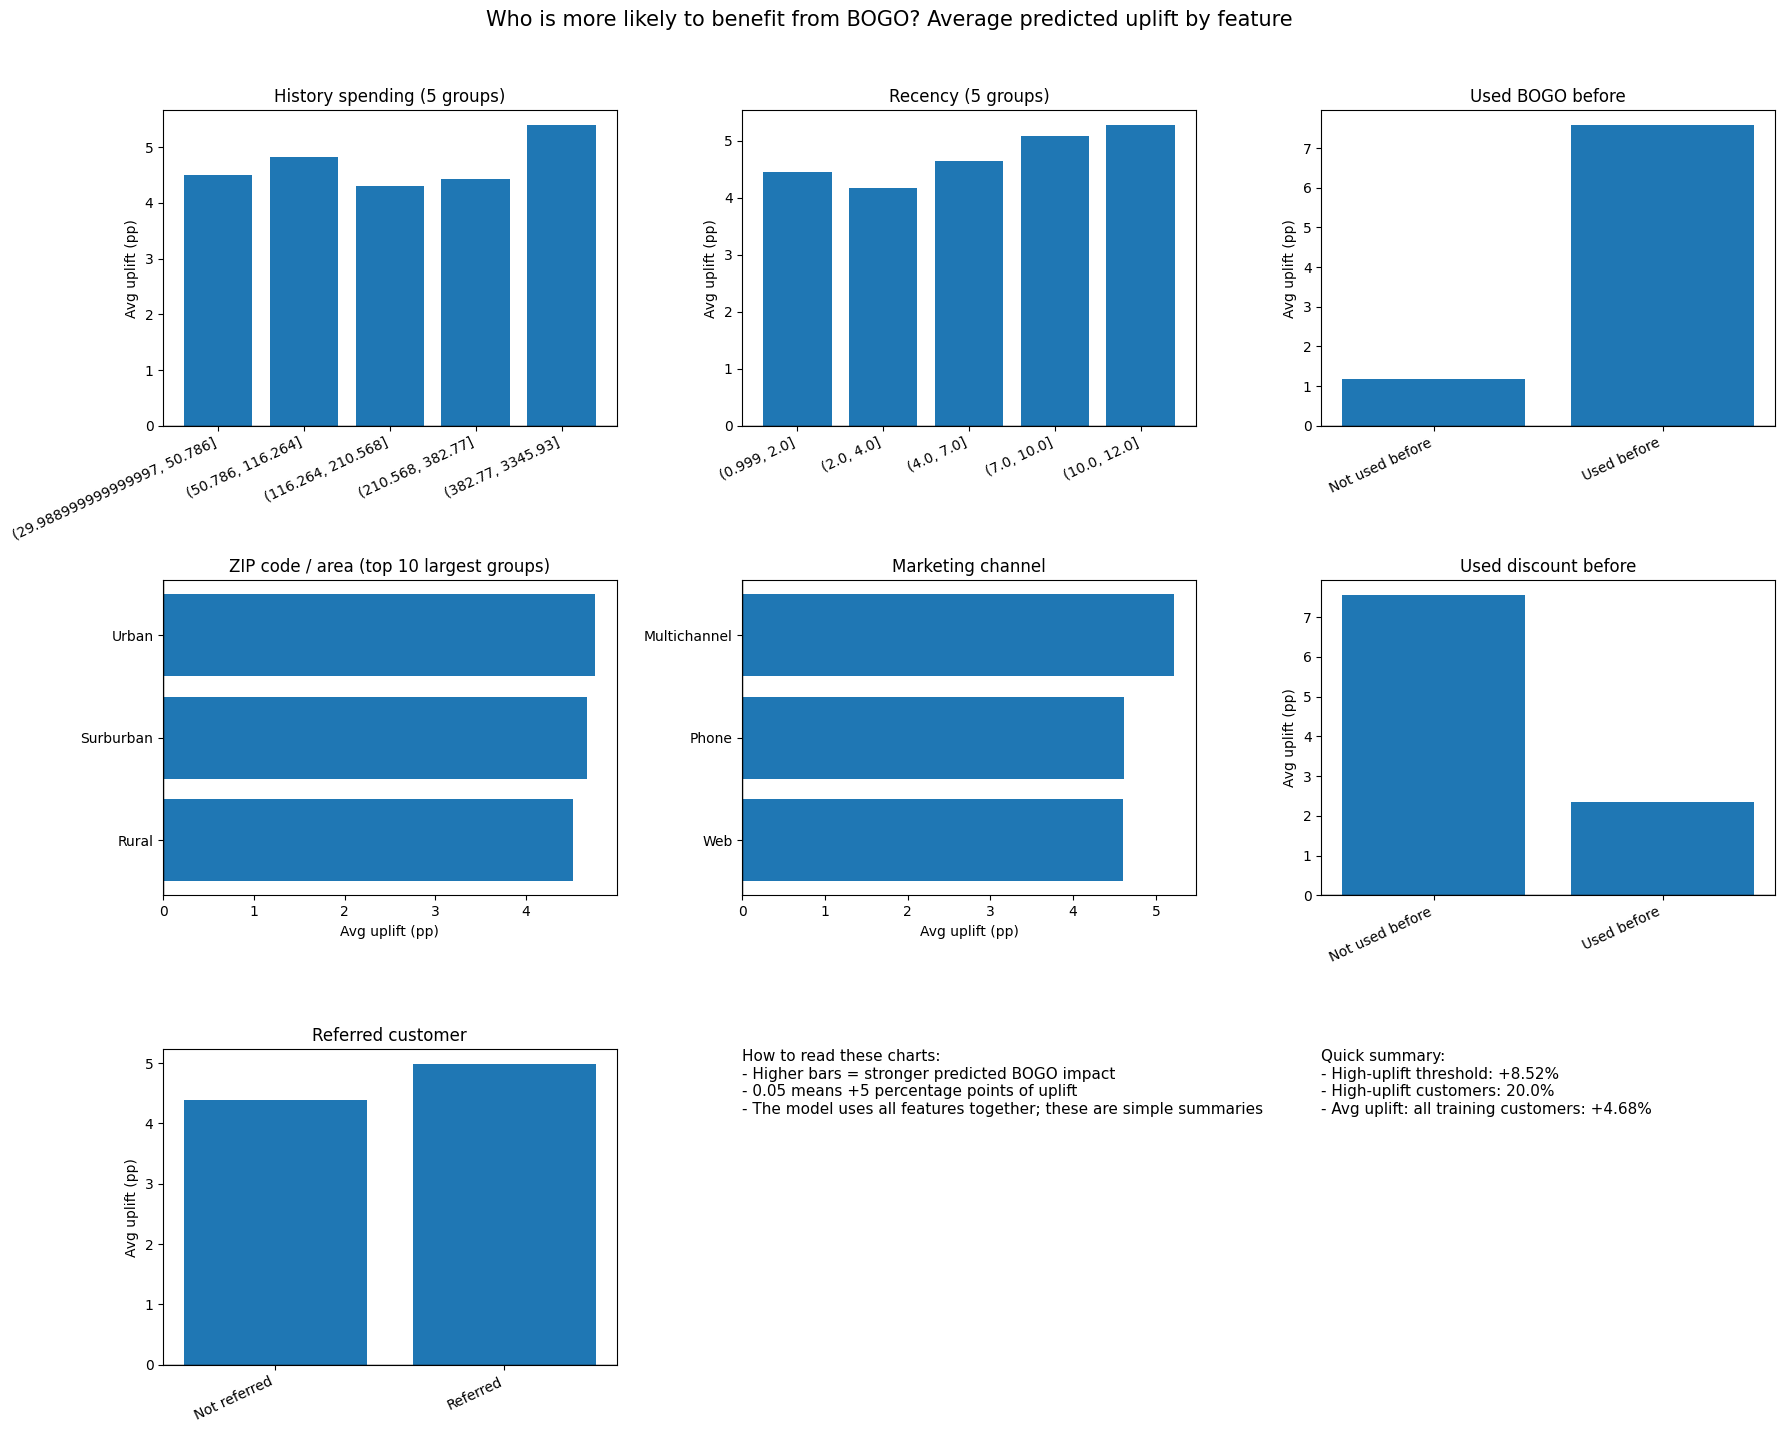

In [16]:
# Profile predicted uplift across key customer features using charts only (no tree).
high_cutoff = float(np.quantile(uplift_train, 0.80))
profile = raw.iloc[train_idx].reset_index(drop=True).copy()
profile['predicted_uplift'] = uplift_train
profile['high_uplift'] = uplift_train >= high_cutoff

print(f'High-uplift threshold (top ~20% of training customers): {high_cutoff:+.2%}')

# ---------- Build summary datasets ----------
# 1) Numeric features: group into quantile bins for easier reading.
profile['history_bin'] = pd.qcut(profile['history'], q=5, duplicates='drop')
profile['recency_bin'] = pd.qcut(profile['recency'], q=5, duplicates='drop')

history_summary = (profile.groupby('history_bin', observed=False)
    .agg(avg_uplift=('predicted_uplift', 'mean'), customers=('predicted_uplift', 'size'))
    .reset_index())
history_summary['label'] = history_summary['history_bin'].astype(str)

recency_summary = (profile.groupby('recency_bin', observed=False)
    .agg(avg_uplift=('predicted_uplift', 'mean'), customers=('predicted_uplift', 'size'))
    .reset_index())
recency_summary['label'] = recency_summary['recency_bin'].astype(str)

# 2) Binary features.
def binary_summary(column, yes_label='Yes', no_label='No'):
    d = (profile.groupby(column, observed=False)
         .agg(avg_uplift=('predicted_uplift', 'mean'), customers=('predicted_uplift', 'size'))
         .reset_index())
    d['label'] = d[column].map({0: no_label, 1: yes_label}).fillna(d[column].astype(str))
    return d

used_bogo_summary = binary_summary('used_bogo', yes_label='Used before', no_label='Not used before')
used_discount_summary = binary_summary('used_discount', yes_label='Used before', no_label='Not used before')
referral_summary = binary_summary('is_referral', yes_label='Referred', no_label='Not referred')

# 3) Categorical features: keep the largest groups for readability.
def top_category_summary(column, top_n=10):
    d = (profile.groupby(column, dropna=False)
         .agg(avg_uplift=('predicted_uplift', 'mean'), customers=('predicted_uplift', 'size'))
         .reset_index()
         .sort_values('customers', ascending=False)
         .head(top_n)
         .copy())
    d['label'] = d[column].astype(str)
    return d

zip_summary = top_category_summary('zip_code', top_n=10)
channel_summary = top_category_summary('channel', top_n=10)

# ---------- Plot dashboard ----------
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()

def add_vertical_bar(ax, data, title):
    vals = 100 * data['avg_uplift'].to_numpy()
    ax.bar(range(len(data)), vals)
    ax.axhline(0, color='black', linewidth=1)
    ax.set_xticks(range(len(data)))
    ax.set_xticklabels(data['label'], rotation=25, ha='right')
    ax.set_ylabel('Avg uplift (pp)')
    ax.set_title(title)

# numeric + binary charts
add_vertical_bar(axes[0], history_summary, 'History spending (5 groups)')
add_vertical_bar(axes[1], recency_summary, 'Recency (5 groups)')
add_vertical_bar(axes[2], used_bogo_summary, 'Used BOGO before')
add_vertical_bar(axes[5], used_discount_summary, 'Used discount before')
add_vertical_bar(axes[6], referral_summary, 'Referred customer')

# category charts as horizontal bars for readability
for ax, data, title in [
    (axes[3], zip_summary.sort_values('avg_uplift'), 'ZIP code / area (top 10 largest groups)'),
    (axes[4], channel_summary.sort_values('avg_uplift'), 'Marketing channel'),
]:
    ax.barh(data['label'], 100 * data['avg_uplift'])
    ax.axvline(0, color='black', linewidth=1)
    ax.set_xlabel('Avg uplift (pp)')
    ax.set_title(title)

# Use the last two panels for a concise legend / explanation.
axes[7].axis('off')
axes[7].text(
    0, 1,
    'How to read these charts:\n'
    '- Higher bars = stronger predicted BOGO impact\n'
    '- 0.05 means +5 percentage points of uplift\n'
    '- The model uses all features together; these are simple summaries',
    va='top', fontsize=11
)

high_profile = pd.DataFrame({
    'Metric': ['High-uplift threshold', 'High-uplift customers', 'Avg uplift: all training customers'],
    'Value': [f'{high_cutoff:+.2%}', f'{profile["high_uplift"].mean():.1%}', f'{profile["predicted_uplift"].mean():+.2%}']
})
axes[8].axis('off')
axes[8].text(
    0, 1,
    'Quick summary:\n'
    + '\n'.join(f"- {m}: {v}" for m, v in zip(high_profile['Metric'], high_profile['Value'])),
    va='top', fontsize=11
)

plt.suptitle('Who is more likely to benefit from BOGO? Average predicted uplift by feature', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()



The charts show how much BOGO is predicted to increase customers' chances of purchasing, based on their characteristics.

| Customer feature        | Key finding                                                                                                             |
| ----------------------- | ----------------------------------------------------------------------------------------------------------------------- |
| Past spending           | Customers with the highest past spending show slightly higher uplift (\~5.4 pp), but differences are relatively small.  |
| Recency                 | Customers who haven't purchased for longer tend to respond better to BOGO (\~5.2 pp).                                   |
| Previous BOGO usage     | Strongest difference: Previous BOGO users have much higher uplift (\~7.5 pp) than non-users (\~1.2 pp).                 |
| ZIP code / area         | Urban customers show slightly higher uplift (\~4.8 pp), but differences between areas are small.                        |
| Marketing channel       | Multichannel customers respond slightly better (\~5.2 pp) than phone or web customers (\~4.6 pp).                       |
| Previous discount usage | Customers who haven't used discounts before show much higher uplift (\~7.5 pp) than previous discount users (\~2.3 pp). |
| Referral                | Referred customers show slightly higher uplift (\~5.0 pp) than non-referred customers (\~4.4 pp).                       |

pp = percentage points. All figures are approximate model predictions from training data, not observed causal effects for each segment.

Key takeaways:

1. Past promotion behavior matters most: Previous BOGO users and customers who haven't used discounts show the highest predicted uplift.
2. Spending, recency, location, channel, and referrals show smaller differences in predicted BOGO response.

Business conclusion: Previous BOGO users and customers who haven't used discounts are promising segments to investigate for BOGO targeting.

Therefore, based on these charts, we will compare the **CausalForestDML** with 2 baselines (**Actual offers** & **No one**) and 4 simple rules (**High spending**, **Used BOGO before**, **Not used discount before** & **Not purchased for a long time**)

However, higher uplift doesn't always mean higher profit. We still need to account for sending costs and free-item costs before deciding which customers should receive BOGO.

### 3.3 Did CausalForestDML beat the actual historical campaign?

We compare **one actual campaign benchmark** with **seven possible targeting strategies**, including CausalForestDML, using the **same test customers**.

| Comparison | Who gets BOGO? | How we measure profit |
|---|---|---|
| **Historical campaign (actual offers)** | Customers who **actually received BOGO** in the original campaign | **Observed** purchases and offers, with assumed costs |
| **CausalForestDML** | Customers with positive **predicted extra profit** | Estimated counterfactual |
| Everyone | Every customer | Estimated counterfactual |
| No one | Nobody (**baseline**) | Estimated counterfactual |
| Historical spending > average | Customers whose past spending exceeds the **training-set** average | Estimated counterfactual |
| Used BOGO before | Customers who previously used BOGO | Estimated counterfactual |
| Not used discount before | Customers who have **not** previously used a discount | Estimated counterfactual |
| Recency > average | Customers who have not purchased for longer than the **training-set** average | Estimated counterfactual |

**Profit assumptions:** A normal purchase earns **USD 25 revenue − USD 5 cost of the paid item = USD 20 contribution**. A BOGO purchase also costs **USD 5 for the free item**. Every offer sent costs **USD 0.20**, even when there is no purchase.

**Simple CausalForestDML targeting rule:**

`Expected extra profit = USD 20 × predicted uplift − USD 0.20 − USD 5 × predicted chance of buying with BOGO`

**Send BOGO only when expected extra profit is positive.** We report profit over the **actual test-set size**, not scaled to 10,000 customers.

**Important:** The original campaign's result is **observed under assumed costs**, while the results for proposed strategies are **model-based estimates**. We should not pretend these were eight real campaigns.

In [17]:
# Train additional conversion models ONLY on TRAIN data, one per historical offer.
mu_models = {}
for action in (0, 1):
    model = conversion_model()
    model.fit(X_train.loc[t_train == action], y_train[t_train == action])
    mu_models[action] = model

def predicted_conversion(X):
    return (mu_models[0].predict_proba(X)[:, 1],
            mu_models[1].predict_proba(X)[:, 1])

mu0_test, mu1_test = predicted_conversion(X_test)

def expected_extra_profit(uplift, p_convert_bogo,
                          send_cost=SEND_COST_PER_OFFER, item_cost=ITEM_COST):
    # Paid and free items are the same product at the same unit cost.
    return ((REVENUE_PER_ORDER - item_cost) * np.asarray(uplift)
            - send_cost
            - item_cost * BOGO_REDEMPTION_PER_CONVERSION * np.asarray(p_convert_bogo))

def forest_policy(send_cost=SEND_COST_PER_OFFER, item_cost=ITEM_COST):
    return (expected_extra_profit(uplift_test, mu1_test,
                                  send_cost, item_cost) > 0).astype(int)

n_test = len(y_test)
test_customers = raw.iloc[test_idx].reset_index(drop=True)
base_rules = {
    'Everyone': np.ones(n_test, dtype=int),
    'No one': np.zeros(n_test, dtype=int),
    'Historical spending > average': (
        test_customers['history'] > AVG_SPENDING).to_numpy(dtype=int),
    'Used BOGO before': (
        test_customers['used_bogo'] == 1).to_numpy(dtype=int),
    'Not used discount before': (
        test_customers['used_discount'] == 0).to_numpy(dtype=int),
    'Recency > average': (
        test_customers['recency'] > AVG_RECENCY).to_numpy(dtype=int),
}

def make_policies(send_cost=SEND_COST_PER_OFFER, item_cost=ITEM_COST):
    targeted = forest_policy(send_cost, item_cost)
    return {
        FOREST_LABEL: targeted,
        'Everyone': base_rules['Everyone'],
        'No one': base_rules['No one'],
        'Historical spending > average': base_rules['Historical spending > average'],
        'Used BOGO before': base_rules['Used BOGO before'],
        'Not used discount before': base_rules['Not used discount before'],
        'Recency > average': base_rules['Recency > average'],
    }

HISTORICAL_LABEL = 'Historical campaign (actual offers)'
policies = make_policies()
print(f'CausalForestDML targets {policies[FOREST_LABEL].mean():.1%} of test customers.')

CausalForestDML targets 48.7% of test customers.


In [18]:
def aipw_conversion(policy, treatment, outcome, mu0, mu1, propensity=P_BOGO):
    """Estimate conversions under a policy using held-out, historically assigned offers.

    Requires randomized historical assignment (or valid conditional assignment estimates).
    Individual returned values are statistical contributions, NOT probabilities.
    """
    action = np.asarray(policy, dtype=int)
    observed_action = np.asarray(treatment, dtype=int)
    observed_purchase = np.asarray(outcome, dtype=float)
    expected = np.where(action == 1, mu1, mu0)
    action_chance = np.where(action == 1, propensity, 1 - propensity)
    return (expected + (observed_action == action)
            * (observed_purchase - expected) / action_chance)

def policy_components(policy, send_cost=SEND_COST_PER_OFFER, item_cost=ITEM_COST):
    """Estimated contribution for each test row; sum results for policy totals."""
    action = np.asarray(policy, dtype=int)
    conversion = aipw_conversion(action, t_test, y_test, mu0_test, mu1_test)
    send_expense = action * send_cost
    # AIPW-adjusted BOGO conversions estimate redemption volume, not individual probabilities.
    free_item_expense = (action * conversion * item_cost
                         * BOGO_REDEMPTION_PER_CONVERSION)
    contribution = ((REVENUE_PER_ORDER - item_cost) * conversion
                    - send_expense - free_item_expense)
    return conversion, send_expense, free_item_expense, contribution

def actual_campaign_components(send_cost=SEND_COST_PER_OFFER, item_cost=ITEM_COST):
    """OBSERVED campaign on the test set: use actual historical offers and purchases.

    Never run observed historical actions through AIPW as though they were a new
    customer targeting rule: those actions come from the recorded assignment.
    Financial amounts use the notebook's assumed unit costs.
    """
    actual_offer = np.asarray(t_test, dtype=int)
    actual_purchase = np.asarray(y_test, dtype=float)
    sending = actual_offer * send_cost
    gifts = (actual_offer * actual_purchase * item_cost
             * BOGO_REDEMPTION_PER_CONVERSION)
    contribution = ((REVENUE_PER_ORDER - item_cost) * actual_purchase
                    - sending - gifts)
    return actual_purchase, sending, gifts, contribution

def mean_ci(samples):
    v = np.asarray(samples, dtype=float)
    average = float(v.mean())
    se = float(v.std(ddof=1) / np.sqrt(len(v)))
    return average, average - 1.96 * se, average + 1.96 * se

Comparison for the same 8,539 TEST customers:
Historical campaign = observed purchases/offers; other rows = estimated alternatives.
No Offer baseline = model-estimated profit if nobody received BOGO.


,Strategy,Result type,Customers targeted (%),Total promotion cost (USD),Total profit (USD),Extra profit vs No Offer (USD)
0,Not used discount before,Estimated (what-if),44.9,3983.83,20103.58,1612.71
1,CausalForestDML (profit targeted),Estimated (what-if),48.7,4146.23,19497.61,1006.75
2,Used BOGO before,Estimated (what-if),55.3,5247.57,19379.80,888.93
3,No one,Estimated (what-if),0.0,0.00,18490.87,0.00
4,Recency > average,Estimated (what-if),50.8,3512.14,18023.62,-467.25
5,Historical campaign (actual offers),Observed (assumed costs),50.1,3995.60,17724.40,-766.47
6,Historical spending > average,Estimated (what-if),34.7,3234.01,17168.21,-1322.66
7,Everyone,Estimated (what-if),100.0,7965.82,17066.26,-1424.60


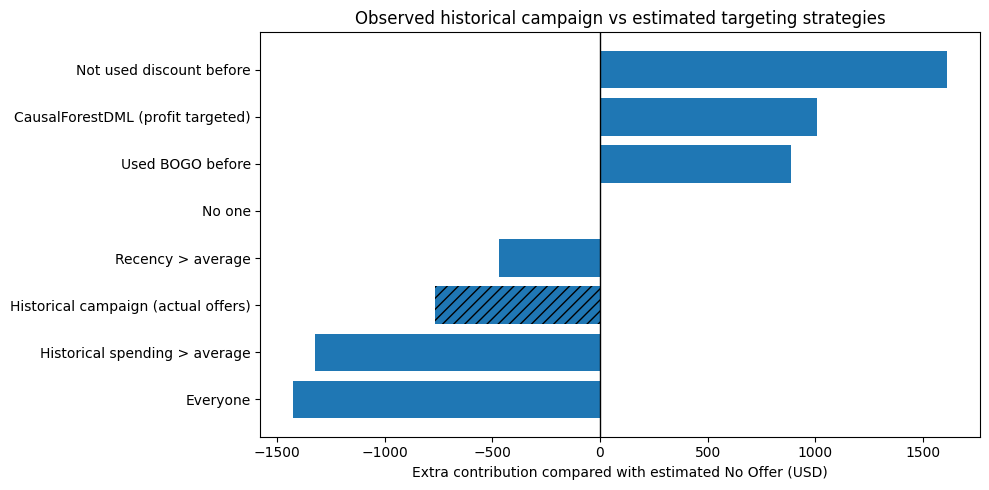

In [19]:
# Observed original campaign vs estimated alternative targeting strategies.
rows = []
no_offer_profit = policy_components(base_rules['No one'])[3]
base_profit_scores = {}

for name, policy in policies.items():
    _, sending, free_items, profit = policy_components(policy)
    base_profit_scores[name] = profit
    rows.append({
        'Strategy': name,
        'Result type': 'Estimated (what-if)',
        'Customers targeted (%)': round(100 * policy.mean(), 1),
        'Total promotion cost (USD )': round(float((sending + free_items).sum()), 2),
        'Total profit (USD )': round(float(profit.sum()), 2),
        'Extra profit vs No Offer (USD )': round(float((profit - no_offer_profit).sum()), 2),
    })

# Original campaign: REAL offers and REAL conversions on the held-out test rows.
_, historical_send, historical_gifts, historical_profit = actual_campaign_components()
base_profit_scores[HISTORICAL_LABEL] = historical_profit
rows.append({
    'Strategy': HISTORICAL_LABEL,
    'Result type': 'Observed (assumed costs)',
    'Customers targeted (%)': round(100 * t_test.mean(), 1),
    'Total promotion cost (USD )': round(float((historical_send + historical_gifts).sum()), 2),
    'Total profit (USD )': round(float(historical_profit.sum()), 2),
    'Extra profit vs No Offer (USD )': round(float((historical_profit - no_offer_profit).sum()), 2),
})

profit_results = (pd.DataFrame(rows)
    .sort_values('Extra profit vs No Offer (USD )', ascending=False)
    .reset_index(drop=True))
print(f'Comparison for the same {n_test:,} TEST customers:')
print('Historical campaign = observed purchases/offers; other rows = estimated alternatives.')
print('No Offer baseline = model-estimated profit if nobody received BOGO.')
display(profit_results)

fig, ax = plt.subplots(figsize=(10, 5))
plot_data = profit_results.sort_values('Extra profit vs No Offer (USD )')
bars = ax.barh(plot_data['Strategy'], plot_data['Extra profit vs No Offer (USD )'])
for bar, name in zip(bars, plot_data['Strategy']):
    if name == HISTORICAL_LABEL:
        bar.set_hatch('///')  # Distinguish observed historical benchmark.
ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('Extra contribution compared with estimated No Offer (USD )')
ax.set_title('Observed historical campaign vs estimated targeting strategies')
plt.tight_layout()
plt.show()


**How to read the comparison:**
- **Customers targeted (%)** — Share of test customers receiving BOGO.
- **Total promotion cost** — Cost of sending offers plus free items for BOGO purchases.
- **Total profit** — Contribution across **all test customers**, including those who would buy without promotion.
- **Extra profit vs No Offer** — Difference compared with the **estimated** profit if nobody received BOGO. Positive is better than no promotion.
- **Result type** — **Observed** means actual campaign offers and purchases (with assumed prices/costs); **Estimated** means what a different policy might have earned.

Key Findings & Conclusion:


1.   **Best strategy:** Targeting customers who **haven't used discounts before** generates the highest estimated extra profit (+1,613).
2.   **CausalForestDML:** ranks second (+1,007). Although it is not the most profitable strategy, its uplift analysis helps identify customers who haven't used discounts before as a highly responsive segment.
3. **Historical campaign** generates approximately (-766) less profit than the estimated No Offer baseline, while offering BOGO to everyone performs even worse (−1,425).


**Business takeaway:** A complex model does not always outperform simple CRM targeting rules. However, **CausalForestDML provides valuable insights into customer behavior**, helping businesses discover promising segments and make more informed, profit-driven targeting decisions.

### 3.4 Cost sensitivity: What if BOGO costs rise from 10% to 50%?

We test five combined BOGO costs **when a customer redeems the offer**.

**Definition:** `Combined cost as a % of USD 25 sale revenue = USD 0.20 sending cost + cost of one free item`.

The free item is the **same product**, so its unit cost also applies to the **paid item**. If a customer receives an offer but does not buy, only the USD 0.20 sending cost applies.

| Combined cost when redeemed | Sending cost per offer | Item cost (paid and free, each) | Sending + free item |
|---|---:|---:|---:|
| **10%** of sale revenue | USD 0.20 | USD 2.30 | USD 2.50 |
| **20%** of sale revenue | USD 0.20 | USD 4.80 | USD 5.00 |
| **30%** of sale revenue | USD 0.20 | USD 7.30 | USD 7.50 |
| **40%** of sale revenue | USD 0.20 | USD 9.80 | USD 10.00 |
| **50%** of sale revenue | USD 0.20 | USD 12.30 | USD 12.50 |

**What changes?** Both the normal order margin and the free-item cost change. CausalForestDML recalculates which customers are profitable to target; simple CRM rules remain fixed. The historical campaign always uses **the offers and purchases actually recorded**—only assumed costs change.

**Base case:** A USD 5.00 free item + USD 0.20 sending expense = **USD 5.20**, or **20.8%** of a USD 25 sale when redeemed.

Extra contribution vs estimated No Offer on the 8,539-customer TEST set (USD):


Combined cost at redemption (%),10,20,30,40,50
Strategy,,,,,
CausalForestDML (profit targeted),3348.98,1004.85,-242.52,-171.71,-4.91
Everyone,2837.79,-1108.87,-5055.53,-9002.20,-12948.86
Historical campaign (actual offers),1365.07,-608.57,-2582.22,-4555.86,-6529.50
Historical spending > average,361.30,-1197.92,-2757.15,-4316.37,-5875.59
No one,0.00,0.00,0.00,0.00,0.00
Not used discount before,4105.77,1797.38,-511.00,-2819.39,-5127.77
Recency > average,1371.54,-331.04,-2033.63,-3736.21,-5438.79
Used BOGO before,4040.64,1122.39,-1795.86,-4714.11,-7632.36


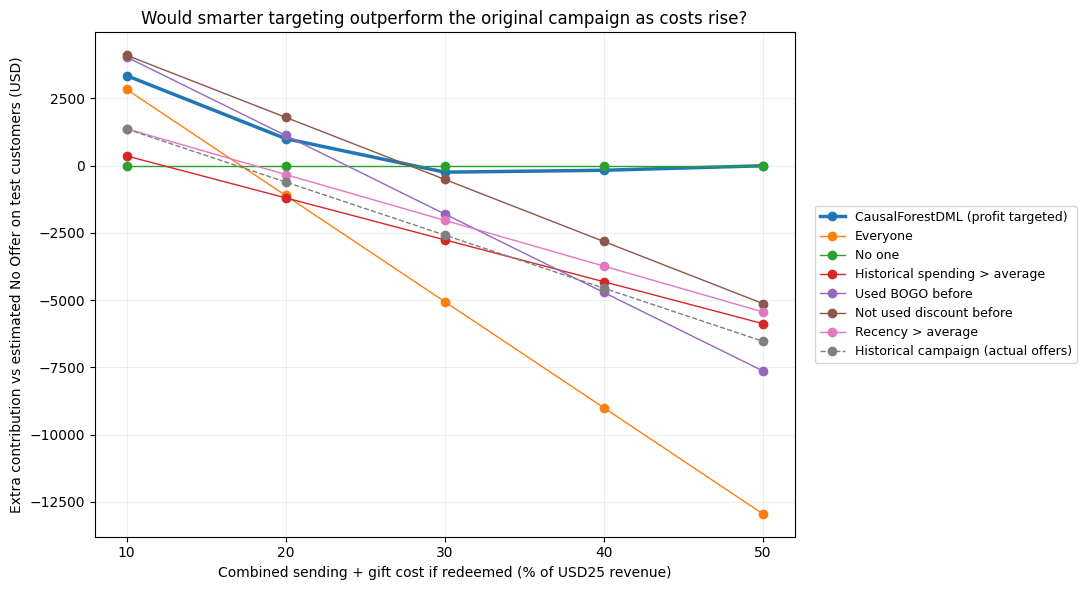

Best estimated implementable rule at each cost:


,Combined cost at redemption (%),Item cost (USD),Strategy,Customers targeted (%),Extra profit vs No Offer (USD)
5,10,2.3,Not used discount before,44.9,4105.77
13,20,4.8,Not used discount before,44.9,1797.38
18,30,7.3,No one,0.0,0.00
26,40,9.8,No one,0.0,0.00
34,50,12.3,No one,0.0,0.00


In [20]:
# Compare the actual historical campaign and alternative targeting policies at each cost.
scenario_rows = []
for rate in COST_RATES:
    sending_per_offer = SEND_COST_PER_OFFER
    # Same product: free item and paid item have the same unit cost.
    scenario_item_cost = rate * REVENUE_PER_ORDER - sending_per_offer
    scenario_policies = make_policies(send_cost=sending_per_offer,
                                     item_cost=scenario_item_cost)
    baseline = policy_components(base_rules['No one'],
                                 send_cost=sending_per_offer,
                                 item_cost=scenario_item_cost)[3]

    for name, policy in scenario_policies.items():
        _, sending, free_items, profit = policy_components(
            policy, send_cost=sending_per_offer, item_cost=scenario_item_cost)
        scenario_rows.append({
            'Combined cost at redemption (%)': int(round(rate * 100)),
            'Item cost (USD )': round(float(scenario_item_cost), 2),
            'Strategy': name,
            'Result type': 'Estimated (what-if)',
            'Customers targeted (%)': round(100 * float(policy.mean()), 1),
            'Extra profit vs No Offer (USD )': float((profit - baseline).sum()),
        })

    # Historical campaign remains its ACTUAL offer allocation and actual purchases.
    _, observed_sending, observed_gifts, observed_profit = actual_campaign_components(
        send_cost=sending_per_offer, item_cost=scenario_item_cost)
    scenario_rows.append({
        'Combined cost at redemption (%)': int(round(rate * 100)),
        'Item cost (USD )': round(float(scenario_item_cost), 2),
        'Strategy': HISTORICAL_LABEL,
        'Result type': 'Observed (assumed costs)',
        'Customers targeted (%)': round(100 * float(t_test.mean()), 1),
        'Extra profit vs No Offer (USD )': float((observed_profit - baseline).sum()),
    })

scenarios = pd.DataFrame(scenario_rows)
print(f'Extra contribution vs estimated No Offer on the {n_test:,}-customer TEST set (USD ):')
scenario_pivot = scenarios.pivot(index='Strategy',
    columns='Combined cost at redemption (%)',
    values='Extra profit vs No Offer (USD )')[[10, 20, 30, 40, 50]].round(2)
display(scenario_pivot)

fig, ax = plt.subplots(figsize=(11, 6))
for name, group in scenarios.groupby('Strategy', sort=False):
    ax.plot(group['Combined cost at redemption (%)'],
            group['Extra profit vs No Offer (USD )'], marker='o',
            linewidth=2.5 if name == FOREST_LABEL else 1,
            linestyle='--' if name == HISTORICAL_LABEL else '-', label=name)
#ax.axhline(0, color='black', linestyle=':', linewidth=1)
ax.set_xticks([10, 20, 30, 40, 50])
ax.set_xlabel('Combined sending + gift cost if redeemed (% of USD 25 revenue)')
ax.set_ylabel('Extra contribution vs estimated No Offer on test customers (USD )')
ax.set_title('Would smarter targeting outperform the original campaign as costs rise?')
ax.grid(alpha=0.2)
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=9)
plt.tight_layout()
plt.show()

# Best DEPLOYABLE rule at each cost. Exclude actual historical allocation as it
# is an observed benchmark, not a policy based on customer features.
implementable = scenarios.loc[scenarios['Strategy'] != HISTORICAL_LABEL]
best_each_cost = (implementable.assign(
        rounded_extra_profit=implementable['Extra profit vs No Offer (USD )'].round(2),
        prefer_no_offer=(implementable['Strategy'] == 'No one').astype(int))
    .sort_values(
        ['Combined cost at redemption (%)',
         'rounded_extra_profit', 'Customers targeted (%)', 'prefer_no_offer'],
        ascending=[True, False, True, False], kind='stable')
    .drop_duplicates('Combined cost at redemption (%)')
    .sort_values('Combined cost at redemption (%)'))
print('Best estimated implementable rule at each cost:')
display(best_each_cost[['Combined cost at redemption (%)',
                        'Item cost (USD )', 'Strategy',
                        'Customers targeted (%)', 'Extra profit vs No Offer (USD )']]
        .round(2))


## 4. Business conclusion

This section answers the four business questions in the same order as Section 1. The comparison uses the same **8,539 held-out test customers** and the base-case assumptions: **USD 25 revenue per paid item, USD 5 cost for each paid and free item, and USD 0.20 per BOGO offer sent**.

### 1. Does CausalForestDML generate more profit than the original campaign?

**Answer:** CausalForestDML looks more profitable than the historical allocation under these assumptions. However, this is a comparison between a **model-based estimate** and an **observed historical result**, not proof that the model would achieve the same improvement in a live campaign.

### 2. Which customer characteristics are associated with higher predicted uplift?

**Answer:** The strongest differences in predicted uplift are associated with customers' previous promotion behavior. Previous BOGO usage and not having used discounts before are the clearest customer patterns associated with higher predicted uplift. We should note that these are **descriptive model predictions**.

### 3. How do profit-based and actual targeting compare with simple CRM rules?

**Answer:** The simple CRM rule **“Not used discount before”** is the best estimated implementable strategy, generating **USD 1,612.71** more contribution than No Offer. It exceeds CausalForestDML's estimated extra contribution by about **USD 605.96**. The actual historical campaign is **USD 766.47 below** the estimated No Offer baseline. Thus, a simple CRM rule performs best in this test-set comparison, while CausalForestDML still provides useful uplift and targeting insights.

### 4. Would the best targeting decision change if BOGO costs increased?

**Answer:** At the tested 10% and 20% cost levels, targeting customers who have not used discounts before remains the best option. At 30% and above, every BOGO strategy has negative estimated extra contribution, so **not sending BOGO** is the better decision. These are the tested scenarios; they do not establish an exact break-even point between 20% and 30%.


---
### Important limitations

- **Original campaign assignment is not verified as randomized:** Causal comparisons require a valid treatment-assignment design or adjustment for all relevant confounders.
- **Observed vs estimated:** The historical row uses observed purchases and assigned offers. Alternative policies and No Offer rely on model-assisted estimates; differences are not actual measured campaign uplifts.
- **Profit is contribution, not company net income:** It excludes unrelated overheads and taxes.
- **Redemptions are not recorded:** We assume every BOGO purchase redeems the free item.
- **Same-product economics:** The free product costs the same as the purchased item in each scenario.
- **Customer profile charts are descriptive:** Differences by spending, recency, ZIP/area, channel, or past behavior do not independently prove causality.
- **Winner selected on the test set:** Comparing several rules and choosing the highest test-set estimate is exploratory and may overstate the winner's advantage. A new randomized CRM test is needed to verify which strategy works best.
- **Model and cost uncertainty:** Estimated effects depend on modeling choices, sample variation and assumed unit economics.

**References:** [EconML CausalForestDML](https://econml.azurewebsites.net/_autosummary/econml.dml.CausalForestDML.html) · [Customer Retention dataset](https://www.kaggle.com/datasets/davinwijaya/customer-retention)